# 95 % conformal band on demand curves

Inspects the conformal band wrapped around Exp5 (`exp5c_conformal_band.py`).

Two interpretations of '95 % containment':

- **Joint sup-norm coverage**: 95 % of test rows have their *entire* curve inside the band. Achieved at q ≈ $925 / band width $1850/MWh.
- **Marginal per-τ coverage**: on average over test rows, 95 % of curve points lie inside the band. Achieved with band width ~$614/MWh (varies per τ).

This notebook reads `experiments/proposals_top5/band_predictions.pkl` and plots 4 random test auctions with both bands overlaid.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from aemo_curves.config import DEFAULT_QUANTITY_GRID

plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

BAND_FILE = Path('../experiments/proposals_top5/band_predictions.pkl')
SUMMARY_FILE = Path('../experiments/proposals_top5/band_q.json')

summary = json.loads(SUMMARY_FILE.read_text())
preds = pd.read_pickle(BAND_FILE)
print('Loaded', len(preds), 'test rows')
print(json.dumps({k: round(v, 4) if isinstance(v, float) else v
                  for k, v in summary.items()
                  if k in ('alpha', 'target_coverage', 'empirical_coverage_2024',
                           'band_width_usd_per_mwh', 'q',
                           'marginal_avg_curve_fraction_inside',
                           'marginal_mean_band_width')}, indent=2))

Loaded 17568 test rows
{
  "alpha": 0.05,
  "target_coverage": 0.95,
  "empirical_coverage_2024": 0.9198,
  "band_width_usd_per_mwh": 1810.2715,
  "q": 905.1357,
  "marginal_avg_curve_fraction_inside": 0.9393,
  "marginal_mean_band_width": 614.3336
}


## Calibration scan: what q gives what empirical coverage

 cal_target          q  empirical_2024  band_width_$_per_MWh
       0.80 734.227854        0.705373           1468.455708
       0.85 792.344955        0.763661           1584.689910
       0.90 866.857899        0.825194           1733.715798
       0.92 893.218757        0.872040           1786.437514
       0.95 905.135742        0.919797           1810.271485
       0.97 917.484769        0.947689           1834.969538
       0.99 925.415434        0.971767           1850.830869


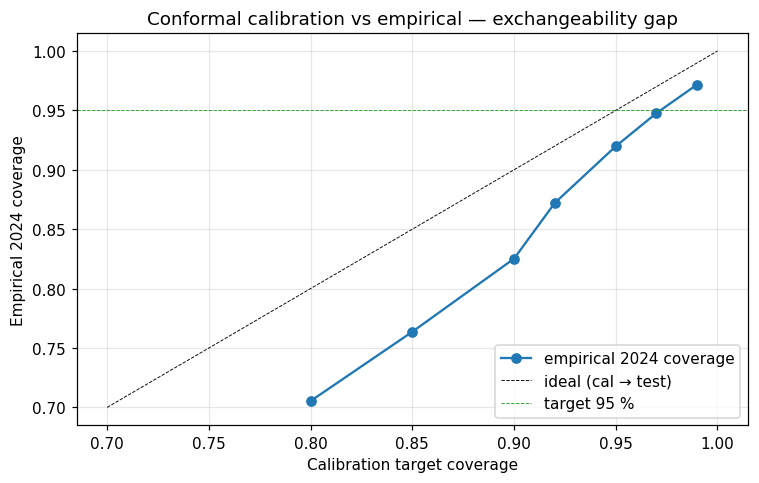

In [2]:
scan = pd.DataFrame({
    'cal_target': summary['scan_targets'],
    'q': [summary['scan_qs'][str(c)] if isinstance(list(summary['scan_qs'].keys())[0], str)
          else summary['scan_qs'][c] for c in summary['scan_targets']],
    'empirical_2024': [
        summary['scan_empirical_test_coverage'][str(c)] if isinstance(list(summary['scan_empirical_test_coverage'].keys())[0], str)
        else summary['scan_empirical_test_coverage'][c]
        for c in summary['scan_targets']
    ],
})
scan['band_width_$_per_MWh'] = 2 * scan['q']
print(scan.to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(scan['cal_target'], scan['empirical_2024'], '-o', label='empirical 2024 coverage')
ax.plot([0.7, 1.0], [0.7, 1.0], 'k--', lw=0.6, label='ideal (cal → test)')
ax.axhline(0.95, color='C2', lw=0.6, ls='--', label='target 95 %')
ax.set_xlabel('Calibration target coverage')
ax.set_ylabel('Empirical 2024 coverage')
ax.set_title('Conformal calibration vs empirical — exchangeability gap')
ax.legend()
plt.tight_layout(); plt.show()

## Joint band (sup-norm) vs marginal band (per-τ)

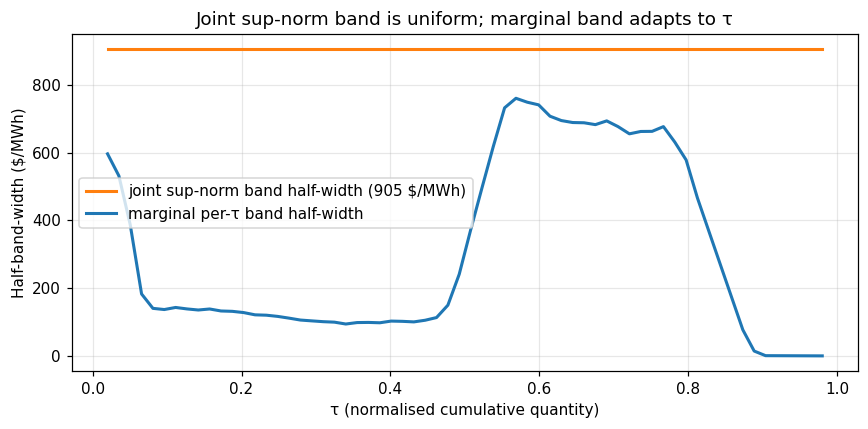

In [3]:
per_tau_q = np.asarray(summary['marginal_per_tau_q'])
tau = DEFAULT_QUANTITY_GRID
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(tau, np.full_like(tau, summary['q']), label=f'joint sup-norm band half-width ({summary["q"]:.0f} $/MWh)',
        color='C1', lw=2)
ax.plot(tau, per_tau_q, label='marginal per-τ band half-width', color='C0', lw=2)
ax.set_xlabel('τ (normalised cumulative quantity)')
ax.set_ylabel('Half-band-width ($/MWh)')
ax.set_title('Joint sup-norm band is uniform; marginal band adapts to τ')
ax.legend()
plt.tight_layout(); plt.show()

## Four random example auctions

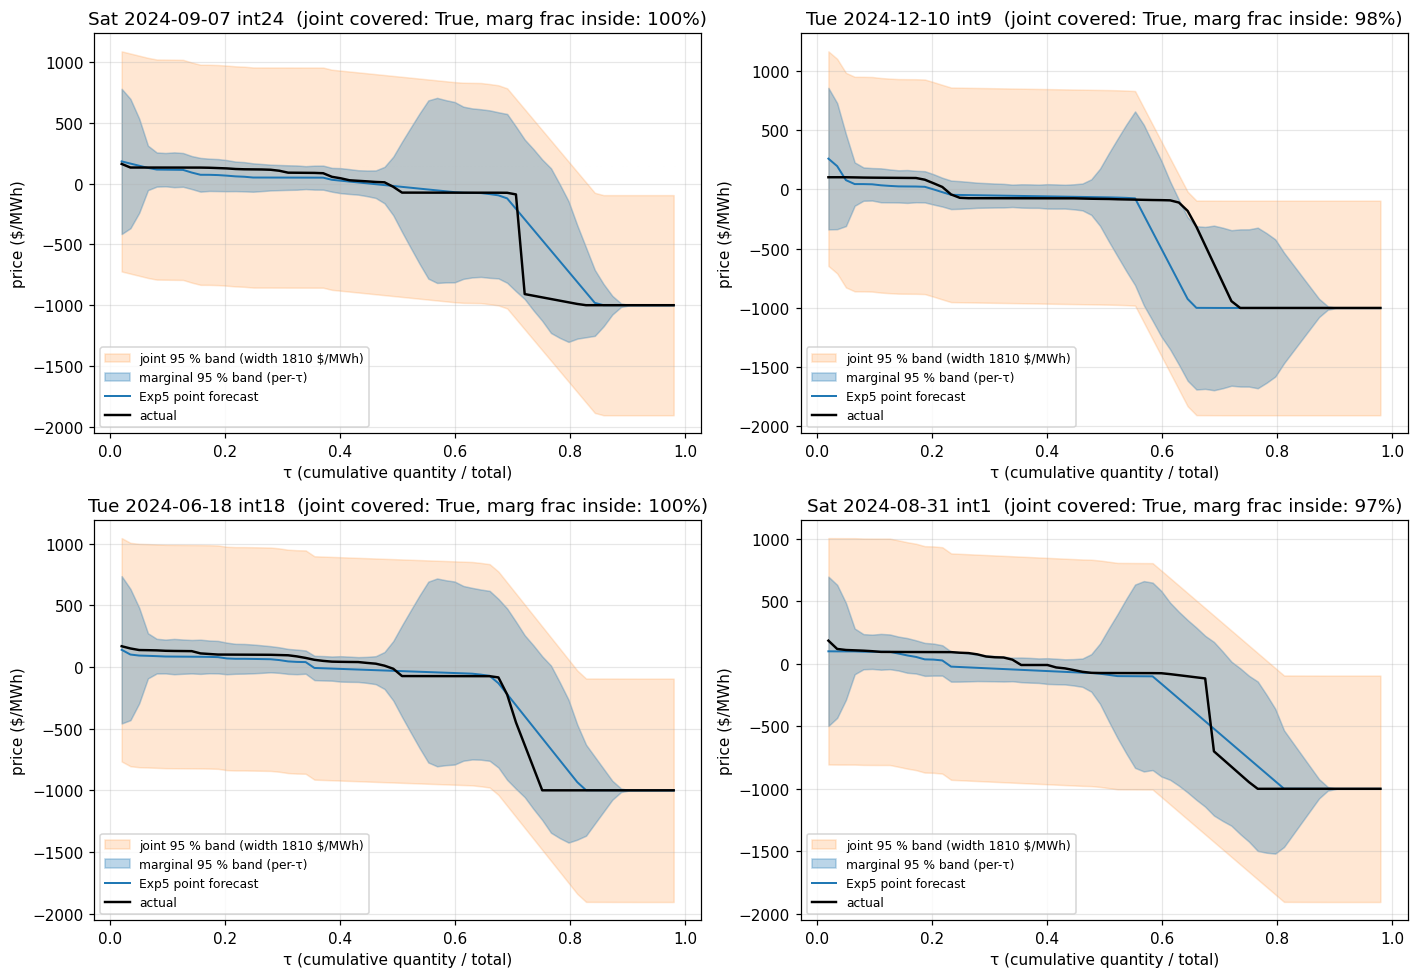

In [4]:
rng = np.random.default_rng()
sample = preds.sample(4, random_state=rng.integers(1_000_000)).reset_index(drop=True)

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, (_, r) in zip(axes.flat, sample.iterrows()):
    true = np.asarray(r['true_embedding'])
    pred = np.asarray(r['pred_embedding'])
    joint_lo = np.asarray(r['band_lower'])
    joint_hi = np.asarray(r['band_upper'])
    marg_lo = np.asarray(r['marginal_band_lower'])
    marg_hi = np.asarray(r['marginal_band_upper'])

    ax.fill_between(tau, joint_lo, joint_hi, color='C1', alpha=0.18,
                    label=f'joint 95 % band (width {2*summary["q"]:.0f} $/MWh)')
    ax.fill_between(tau, marg_lo, marg_hi, color='C0', alpha=0.30,
                    label='marginal 95 % band (per-τ)')
    ax.plot(tau, pred, color='C0', lw=1.3, label='Exp5 point forecast')
    ax.plot(tau, true, color='black', lw=1.6, label='actual')

    date_str = pd.Timestamp(r['Trading Date']).strftime('%a %Y-%m-%d')
    inside_joint = bool(np.all((true >= joint_lo) & (true <= joint_hi)))
    frac_inside = float(np.mean((true >= marg_lo) & (true <= marg_hi)))
    ax.set_title(f'{date_str} int{int(r["Interval Number"])}  '
                 f'(joint covered: {inside_joint}, marg frac inside: {frac_inside:.0%})')
    ax.set_xlabel('τ (cumulative quantity / total)')
    ax.set_ylabel('price ($/MWh)')
    ax.legend(fontsize=8, loc='best')
plt.tight_layout(); plt.show()

## Distribution of per-row fraction-inside (marginal interpretation)

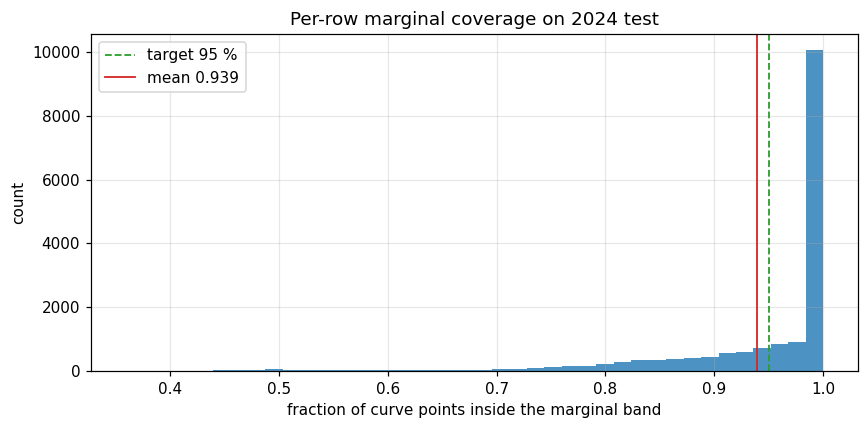

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(preds['marginal_fraction_inside'], bins=40, color='C0', alpha=0.8)
ax.axvline(0.95, color='C2', lw=1.2, ls='--', label='target 95 %')
ax.axvline(preds['marginal_fraction_inside'].mean(), color='C3', lw=1.2,
           label=f"mean {preds['marginal_fraction_inside'].mean():.3f}")
ax.set_xlabel('fraction of curve points inside the marginal band')
ax.set_ylabel('count')
ax.set_title('Per-row marginal coverage on 2024 test')
ax.legend()
plt.tight_layout(); plt.show()